# Adult Census Income Dataset - Predictive Modeling & Fairness Analysis
**Dataset:** Adult Census Income (UCI ML Repository)  
**Random Seed:** 758 | **Train/Test Split:** 70/30  

This notebook covers:
- Data Preprocessing (missing values, encoding, scaling, outliers)
- Part 1: Build (OLS Linear Regression + Logistic Regression)
- Part 2.1: Simpson's Paradox Hunt
- Part 2.2: Omitted-Variable Bias
- Part 2.3: Adversarial Subset Construction
- Part 2.4: Fairness Trade-Off Analysis

## Imports & Configuration

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, ConfusionMatrixDisplay)
import statsmodels.api as sm

SEED = 758
np.random.seed(SEED)

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

---
## Section 0 - Data Loading

In [2]:
col_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
    'income'
]

url_train = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data'
url_test  = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.test'

df_train = pd.read_csv(url_train, header=None, names=col_names,
                        na_values=' ?', skipinitialspace=True)
df_test_raw = pd.read_csv(url_test, header=None, names=col_names,
                        na_values=' ?', skipinitialspace=True, skiprows=1)

# Combine into one dataset (we do our own 70/30 split)
df = pd.concat([df_train, df_test_raw], ignore_index=True)
df['income'] = df['income'].str.strip().str.rstrip('.')

print(f'Combined dataset shape: {df.shape}')
print(f'\nIncome distribution:\n{df["income"].value_counts()}')
df.head()

Combined dataset shape: (48842, 15)

Income distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


---
## Section 1 - Data Preprocessing

### 1a. Missing Values

In [3]:
missing = df.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0])
print(f'\nTotal rows with any missing: {df.isnull().any(axis=1).sum()}')
print(f'Percentage missing: {df.isnull().any(axis=1).sum() / len(df) * 100:.2f}%')

# Strategy: drop rows with missing values
df_clean = df.dropna().reset_index(drop=True)
print(f'Shape after dropping missing: {df_clean.shape}')

Missing values per column:
Series([], dtype: int64)

Total rows with any missing: 0
Percentage missing: 0.00%
Shape after dropping missing: (48842, 15)


### 1b. Target Encoding

In [4]:
df_clean['income_binary'] = (df_clean['income'] == '>50K').astype(int)
print(f'Target distribution:\n{df_clean["income_binary"].value_counts()}')
print(f'Positive class rate: {df_clean["income_binary"].mean():.4f}')

Target distribution:
income_binary
0    37155
1    11687
Name: count, dtype: int64
Positive class rate: 0.2393


### 1c. Categorical Encoding (One-Hot)

In [5]:
categorical_cols = ['workclass', 'education', 'marital_status', 'occupation',
                    'relationship', 'race', 'sex', 'native_country']

df_encoded = pd.get_dummies(df_clean, columns=categorical_cols, drop_first=True)
df_encoded.drop(columns=['income'], inplace=True)
print(f'Shape after one-hot encoding: {df_encoded.shape}')

Shape after one-hot encoding: (48842, 101)


### 1d. Outlier Analysis

In [6]:
numerical_cols = ['age', 'fnlwgt', 'education_num', 'capital_gain',
                  'capital_loss', 'hours_per_week']

outlier_data = []
for col in numerical_cols:
    Q1 = df_encoded[col].quantile(0.25)
    Q3 = df_encoded[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df_encoded[col] < lower) | (df_encoded[col] > upper)).sum()
    pct = n_outliers / len(df_encoded) * 100
    outlier_data.append({'Column': col, 'Q1': Q1, 'Q3': Q3, 'IQR': IQR,
                         'Outliers': n_outliers, 'Pct': f'{pct:.2f}%'})

pd.DataFrame(outlier_data)

,Column,Q1,Q3,IQR,Outliers,Pct
0,age,28.0,48.0,20.0,216,0.44%
1,fnlwgt,117550.5,237642.0,120091.5,1453,2.97%
2,education_num,9.0,12.0,3.0,1794,3.67%
3,capital_gain,0.0,0.0,0.0,4035,8.26%
4,capital_loss,0.0,0.0,0.0,2282,4.67%
5,hours_per_week,40.0,45.0,5.0,13496,27.63%


**Decision:** Outliers retained. `capital_gain` and `capital_loss` are legitimately right-skewed (most values are 0); removing them would distort the income signal. `hours_per_week` has 27.6% outliers because the IQR is narrow (40-45), so the 'outlier' label is misleading.

### 1e. Feature Scaling & Train-Test Split

In [7]:
feature_cols = [c for c in df_encoded.columns if c != 'income_binary']
target_col = 'income_binary'

X = df_encoded[feature_cols].copy()
y = df_encoded[target_col].copy()

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=feature_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.30, random_state=SEED
)

print(f'Train: {X_train.shape[0]} samples ({X_train.shape[0]/len(X_scaled)*100:.1f}%)')
print(f'Test : {X_test.shape[0]} samples ({X_test.shape[0]/len(X_scaled)*100:.1f}%)')
print(f'Train positive rate: {y_train.mean():.4f}')
print(f'Test positive rate : {y_test.mean():.4f}')

# Keep original test data for demographic analysis
test_indices = X_test.index
df_test_original = df_clean.loc[test_indices].reset_index(drop=True)

Train: 34189 samples (70.0%)
Test : 14653 samples (30.0%)
Train positive rate: 0.2390
Test positive rate : 0.2399


---
## Part 1 - Build
### Model A: Linear Regression (OLS)

In [8]:
model_a = LinearRegression()
model_a.fit(X_train, y_train)
y_pred_a_raw = model_a.predict(X_test)

print(f'OLS predictions - min: {y_pred_a_raw.min():.4f}, '
      f'max: {y_pred_a_raw.max():.4f}, '
      f'mean: {y_pred_a_raw.mean():.4f}')

# Threshold at median predicted value
median_pred = np.median(y_pred_a_raw)
y_pred_a_class = (y_pred_a_raw >= median_pred).astype(int)
print(f'Median predicted value (threshold): {median_pred:.4f}')
print(f'Model A classifications: High-risk={y_pred_a_class.sum()}, '
      f'Low-risk={(1-y_pred_a_class).sum()}')

OLS predictions - min: -0.4257, max: 1.6986, mean: 0.2392
Median predicted value (threshold): 0.2261
Model A classifications: High-risk=7327, Low-risk=7326


### Model B: Logistic Regression

In [9]:
model_b = LogisticRegression(max_iter=2000, random_state=SEED, solver='lbfgs')
model_b.fit(X_train, y_train)
y_pred_b_proba = model_b.predict_proba(X_test)[:, 1]
y_pred_b_class = (y_pred_b_proba >= 0.5).astype(int)

print(f'Logistic predictions - min prob: {y_pred_b_proba.min():.4f}, '
      f'max prob: {y_pred_b_proba.max():.4f}, '
      f'mean prob: {y_pred_b_proba.mean():.4f}')
print(f'Model B classifications: High-risk={y_pred_b_class.sum()}, '
      f'Low-risk={(1-y_pred_b_class).sum()}')

Logistic predictions - min prob: 0.0000, max prob: 1.0000, mean prob: 0.2403
Model B classifications: High-risk=2887, Low-risk=11766


### Model Comparison: Agreement / Disagreement

In [10]:
cm_ab = confusion_matrix(y_pred_a_class, y_pred_b_class)
agree = cm_ab[0, 0] + cm_ab[1, 1]
disagree = cm_ab[0, 1] + cm_ab[1, 0]
total = agree + disagree

print('Confusion Matrix (Model A vs Model B):')
print(f'{"":>25s} Model B: Low-risk  Model B: High-risk')
print(f'{"Model A: Low-risk":>25s}    {cm_ab[0,0]:>6d}          {cm_ab[0,1]:>6d}')
print(f'{"Model A: High-risk":>25s}    {cm_ab[1,0]:>6d}          {cm_ab[1,1]:>6d}')
print(f'\nAgreement:    {agree:>6d} ({agree/total*100:.2f}%)')
print(f'Disagreement: {disagree:>6d} ({disagree/total*100:.2f}%)')

acc_a = accuracy_score(y_test, y_pred_a_class)
acc_b = accuracy_score(y_test, y_pred_b_class)
print(f'\nModel A accuracy (vs actual): {acc_a:.4f}')
print(f'Model B accuracy (vs actual): {acc_b:.4f}')

print('\n--- Model A Classification Report ---')
print(classification_report(y_test, y_pred_a_class, target_names=['<=50K', '>50K']))
print('--- Model B Classification Report ---')
print(classification_report(y_test, y_pred_b_class, target_names=['<=50K', '>50K']))

Confusion Matrix (Model A vs Model B):
                          Model B: Low-risk  Model B: High-risk
        Model A: Low-risk      7308              18
       Model A: High-risk      4458            2869

Agreement:     10177 (69.45%)
Disagreement:   4476 (30.55%)

Model A accuracy (vs actual): 0.7121
Model B accuracy (vs actual): 0.8538

--- Model A Classification Report ---
              precision    recall  f1-score   support

       <=50K       0.97      0.64      0.77     11138
        >50K       0.45      0.94      0.61      3515

    accuracy                           0.71     14653
   macro avg       0.71      0.79      0.69     14653
weighted avg       0.85      0.71      0.73     14653

--- Model B Classification Report ---
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91     11138
        >50K       0.74      0.61      0.67      3515

    accuracy                           0.85     14653
   macro avg       0.81      0.77  

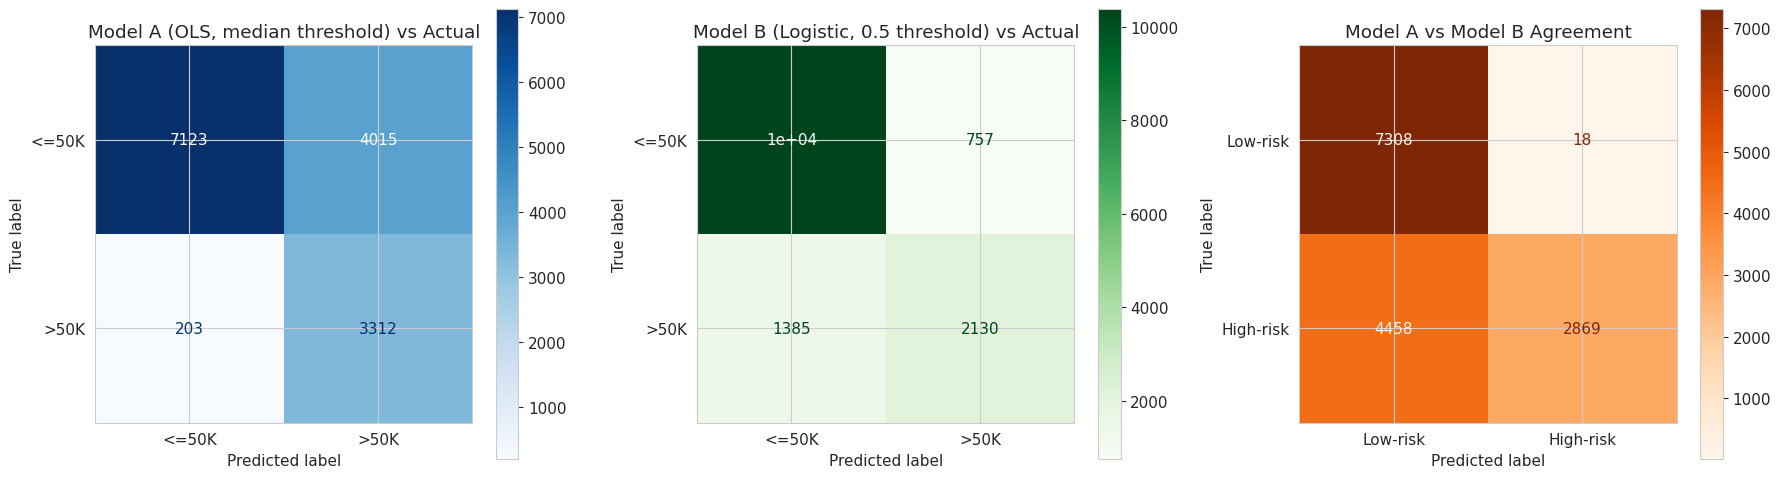

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_a_actual = confusion_matrix(y_test, y_pred_a_class)
ConfusionMatrixDisplay(cm_a_actual, display_labels=['<=50K', '>50K']).plot(ax=axes[0], cmap='Blues')
axes[0].set_title('Model A (OLS, median threshold) vs Actual')

cm_b_actual = confusion_matrix(y_test, y_pred_b_class)
ConfusionMatrixDisplay(cm_b_actual, display_labels=['<=50K', '>50K']).plot(ax=axes[1], cmap='Greens')
axes[1].set_title('Model B (Logistic, 0.5 threshold) vs Actual')

ConfusionMatrixDisplay(cm_ab, display_labels=['Low-risk', 'High-risk']).plot(ax=axes[2], cmap='Oranges')
axes[2].set_title('Model A vs Model B Agreement')

plt.tight_layout()
plt.show()

---
## Part 2.1 - Simpson's Paradox Hunt
**Split variable:** Marital Status (Married vs. Not-Married)  
**Key finding:** The coefficient for `sex_Male` reverses sign from positive (+0.3230) overall to negative (-0.0816) within the married subgroup.

In [12]:
# Prepare data for Simpson's Paradox analysis
df_analysis = df_clean.copy()
cat_cols_analysis = ['workclass', 'education', 'marital_status', 'occupation',
                     'relationship', 'race', 'native_country']

df_simpson = pd.get_dummies(df_analysis, columns=cat_cols_analysis, drop_first=True)
df_simpson['sex_Male'] = (df_simpson['sex'] == 'Male').astype(int)
df_simpson.drop(columns=['income', 'sex'], inplace=True)

feature_cols_simpson = [c for c in df_simpson.columns if c != 'income_binary']
X_full_s = df_simpson[feature_cols_simpson].copy()
y_full_s = df_simpson['income_binary'].copy()

scaler_s = StandardScaler()
X_full_scaled = pd.DataFrame(scaler_s.fit_transform(X_full_s), columns=feature_cols_simpson)

In [13]:
# Split by marital status
married_mask = df_analysis['marital_status'].isin(['Married-civ-spouse', 'Married-AF-spouse'])
not_married_mask = ~married_mask

non_marital_features = [c for c in feature_cols_simpson
                        if not c.startswith('marital_status_')]

X_married = X_full_scaled.loc[married_mask.values][non_marital_features]
y_married = y_full_s.loc[married_mask.values]
X_notmarried = X_full_scaled.loc[not_married_mask.values][non_marital_features]
y_notmarried = y_full_s.loc[not_married_mask.values]
X_full_nm = X_full_scaled[non_marital_features]

print(f'Married:     {X_married.shape[0]} samples, positive rate: {y_married.mean():.4f}')
print(f'Not Married: {X_notmarried.shape[0]} samples, positive rate: {y_notmarried.mean():.4f}')

# Fit three logistic regressions
lr_full_nm = LogisticRegression(max_iter=2000, random_state=SEED, solver='lbfgs')
lr_full_nm.fit(X_full_nm, y_full_s)

lr_married = LogisticRegression(max_iter=2000, random_state=SEED, solver='lbfgs')
lr_married.fit(X_married, y_married)

lr_notmarried = LogisticRegression(max_iter=2000, random_state=SEED, solver='lbfgs')
lr_notmarried.fit(X_notmarried, y_notmarried)

coef_full_nm = dict(zip(non_marital_features, lr_full_nm.coef_[0]))
coef_married = dict(zip(non_marital_features, lr_married.coef_[0]))
coef_notmarried = dict(zip(non_marital_features, lr_notmarried.coef_[0]))

print(f'\n{"Predictor":<35s} {"Full":>10s} {"Married":>10s} {"Not-Married":>12s}')
print('-' * 70)
for pred in ['age', 'education_num', 'hours_per_week', 'capital_gain',
             'sex_Male', 'capital_loss', 'fnlwgt']:
    if pred in coef_full_nm:
        c_f = coef_full_nm[pred]
        c_m = coef_married[pred]
        c_nm = coef_notmarried[pred]
        marker = '  *** SIGN REVERSAL ***' if (c_m > 0 and c_nm < 0) or (c_m < 0 and c_nm > 0) else ''
        print(f'{pred:<35s} {c_f:>10.4f} {c_m:>10.4f} {c_nm:>12.4f}{marker}')

Married:     22416 samples, positive rate: 0.4460
Not Married: 26426 samples, positive rate: 0.0639

Predictor                                 Full    Married  Not-Married
----------------------------------------------------------------------
age                                     0.3741     0.2942       0.5922
education_num                           0.5576     0.5342       0.6389
hours_per_week                          0.3628     0.3045       0.5183
capital_gain                            2.3624     2.1291       2.7062
sex_Male                                0.3230    -0.0816       0.3053  *** SIGN REVERSAL ***
capital_loss                            0.2605     0.2654       0.2504
fnlwgt                                  0.0806     0.0914       0.0343


In [14]:
# Statsmodels for confidence intervals
key_feats_ci = ['age', 'education_num', 'hours_per_week', 'capital_gain',
                'capital_loss', 'sex_Male']

# Full model
X_ci_full = sm.add_constant(X_full_scaled[key_feats_ci])
logit_full = sm.Logit(y_full_s, X_ci_full).fit(disp=0)
print('--- Full Model ---')
print(logit_full.summary2().tables[1][['Coef.', '[0.025', '0.975]']])

# Split by sex for additional CI analysis
male_mask = df_analysis['sex'] == 'Male'
female_mask = df_analysis['sex'] == 'Female'

key_feats_nosex = ['age', 'education_num', 'hours_per_week', 'capital_gain', 'capital_loss']

X_male = X_full_scaled.loc[male_mask.values]
y_male = y_full_s.loc[male_mask.values]
X_female = X_full_scaled.loc[female_mask.values]
y_female = y_full_s.loc[female_mask.values]

X_ci_male = sm.add_constant(X_male[key_feats_nosex])
logit_male = sm.Logit(y_male, X_ci_male).fit(disp=0)
print('\n--- Male Subgroup ---')
print(logit_male.summary2().tables[1][['Coef.', '[0.025', '0.975]']])

X_ci_female = sm.add_constant(X_female[key_feats_nosex])
logit_female = sm.Logit(y_female, X_ci_female).fit(disp=0)
print('\n--- Female Subgroup ---')
print(logit_female.summary2().tables[1][['Coef.', '[0.025', '0.975]']])

--- Full Model ---
                   Coef.    [0.025    0.975]
const          -1.435792 -1.467244 -1.404341
age             0.563290  0.536033  0.590547
education_num   0.858022  0.829447  0.886597
hours_per_week  0.412540  0.386001  0.439078
capital_gain    2.377671  2.259878  2.495464
capital_loss    0.266555  0.245319  0.287790
sex_Male        0.553920  0.523723  0.584117

--- Male Subgroup ---
                   Coef.    [0.025    0.975]
const          -1.077197 -1.111690 -1.042704
age             0.617067  0.585758  0.648375
education_num   0.845725  0.814158  0.877293
hours_per_week  0.456154  0.426016  0.486292
capital_gain    2.277982  2.141856  2.414109
capital_loss    0.259574  0.235548  0.283600

--- Female Subgroup ---
                   Coef.    [0.025    0.975]
const          -2.211259 -2.281617 -2.140900
age             0.391445  0.334486  0.448403
education_num   0.935251  0.866700  1.003802
hours_per_week  0.251375  0.192886  0.309863
capital_gain    2.644426  2.41060

---
## Part 2.2 - Omitted-Variable Bias
**Dropped variable:** `marital_status` (all related dummies)

In [15]:
marital_dummies = [c for c in feature_cols if c.startswith('marital_status_')]
print(f'Dropped variable: marital_status')
print(f'Dummies removed: {marital_dummies}')

# Full model coefficients
coef_full_all = dict(zip(feature_cols, model_b.coef_[0]))

# Reduced model
reduced_features = [c for c in feature_cols if c not in marital_dummies]
X_train_reduced = X_train[reduced_features]
X_test_reduced = X_test[reduced_features]

model_b_reduced = LogisticRegression(max_iter=2000, random_state=SEED, solver='lbfgs')
model_b_reduced.fit(X_train_reduced, y_train)
coef_reduced = dict(zip(reduced_features, model_b_reduced.coef_[0]))

# Compare coefficients
compare_predictors = ['age', 'education_num', 'hours_per_week', 'capital_gain',
                      'capital_loss', 'fnlwgt']
sex_dummies = [c for c in feature_cols if c.startswith('sex_')]
relationship_dummies = [c for c in feature_cols if c.startswith('relationship_')]
compare_predictors += sex_dummies + relationship_dummies[:3]

ovb_results = []
print(f'\n{"Predictor":<45s} {"Full":>10s} {"Reduced":>10s} {"%Change":>10s}')
print('-' * 80)
for pred in compare_predictors:
    if pred in coef_full_all and pred in coef_reduced:
        c_full = coef_full_all[pred]
        c_red = coef_reduced[pred]
        pct = ((c_red - c_full) / abs(c_full)) * 100 if abs(c_full) > 1e-6 else float('inf')
        print(f'{pred:<45s} {c_full:>10.4f} {c_red:>10.4f} {pct:>+10.1f}%')
        ovb_results.append({'predictor': pred, 'full': c_full, 'reduced': c_red, 'pct_change': pct})

ovb_df = pd.DataFrame(ovb_results)
ovb_df['abs_pct_change'] = ovb_df['pct_change'].abs()
most_shifted = ovb_df.sort_values('abs_pct_change', ascending=False).iloc[0]
print(f'\nMost shifted: {most_shifted["predictor"]} ({most_shifted["pct_change"]:+.1f}%)')

acc_full = accuracy_score(y_test, model_b.predict(X_test))
acc_reduced = accuracy_score(y_test, model_b_reduced.predict(X_test_reduced))
print(f'Full model accuracy:    {acc_full:.4f}')
print(f'Reduced model accuracy: {acc_reduced:.4f}')

Dropped variable: marital_status
Dummies removed: ['marital_status_Married-AF-spouse', 'marital_status_Married-civ-spouse', 'marital_status_Married-spouse-absent', 'marital_status_Never-married', 'marital_status_Separated', 'marital_status_Widowed']

Predictor                                           Full    Reduced    %Change
--------------------------------------------------------------------------------
age                                               0.3478     0.3833      +10.2%
education_num                                     0.5287     0.5411       +2.3%
hours_per_week                                    0.3540     0.3583       +1.2%
capital_gain                                      2.3590     2.3585       -0.0%
capital_loss                                      0.2645     0.2634       -0.4%
fnlwgt                                            0.0787     0.0773       -1.7%
sex_Male                                          0.3395     0.3265       -3.8%
relationship_Not-in-family   

---
## Part 2.3 - Adversarial Subset Construction

In [16]:
y_test_arr = y_test.values
proba_test = y_pred_b_proba

fp_mask = (proba_test >= 0.75) & (y_test_arr == 0)
fn_mask = (proba_test <= 0.25) & (y_test_arr == 1)
adversarial_mask = fp_mask | fn_mask

n_adversarial = adversarial_mask.sum()
n_test = len(y_test_arr)
print(f'Total test samples: {n_test}')
print(f'High-confidence wrong predictions: {n_adversarial} ({n_adversarial/n_test*100:.2f}%)')
print(f'  False positives (P>=0.75, actual=0): {fp_mask.sum()}')
print(f'  False negatives (P<=0.25, actual=1): {fn_mask.sum()}')

# Sample 50 rows
adversarial_indices = np.where(adversarial_mask)[0]
rng = np.random.RandomState(SEED)
sampled_indices = rng.choice(adversarial_indices, size=50, replace=False) if len(adversarial_indices) > 50 else adversarial_indices

df_adversarial = df_test_original.iloc[sampled_indices].copy()
df_adversarial['predicted_prob'] = proba_test[sampled_indices]
df_adversarial['actual'] = y_test_arr[sampled_indices]
df_adversarial['error_type'] = np.where(proba_test[sampled_indices] >= 0.75, 'False Positive', 'False Negative')

Total test samples: 14653
High-confidence wrong predictions: 739 (5.04%)
  False positives (P>=0.75, actual=0): 170
  False negatives (P<=0.25, actual=1): 569


In [17]:
# Demographics comparison
print(f'Sampled adversarial subset: {len(df_adversarial)} rows')
print(f'  False Positives: {(df_adversarial["error_type"] == "False Positive").sum()}')
print(f'  False Negatives: {(df_adversarial["error_type"] == "False Negative").sum()}')

print(f'\nAge: Adversarial mean={df_adversarial["age"].mean():.1f}, Full test mean={df_test_original["age"].mean():.1f}')

print(f'\nSex distribution:')
for s in ['Male', 'Female']:
    a = (df_adversarial['sex'] == s).mean() * 100
    f = (df_test_original['sex'] == s).mean() * 100
    print(f'  {s}: Adversarial={a:.1f}%, Full test={f:.1f}%')

print(f'\nMarital status:')
for m in ['Married-civ-spouse', 'Never-married', 'Divorced']:
    a = (df_adversarial['marital_status'] == m).mean() * 100
    f = (df_test_original['marital_status'] == m).mean() * 100
    print(f'  {m}: Adversarial={a:.1f}%, Full test={f:.1f}%')

# Common characteristics
df_fp = df_adversarial[df_adversarial['error_type'] == 'False Positive']
df_fn = df_adversarial[df_adversarial['error_type'] == 'False Negative']

if len(df_fp) > 0:
    print(f'\nFalse Positives ({len(df_fp)} rows):')
    print(f'  % Married-civ-spouse: {(df_fp["marital_status"]=="Married-civ-spouse").mean()*100:.1f}%')
    print(f'  % Male: {(df_fp["sex"]=="Male").mean()*100:.1f}%')
    print(f'  Mean education_num: {df_fp["education_num"].mean():.1f}')
    print(f'  Mean hours_per_week: {df_fp["hours_per_week"].mean():.1f}')
    print(f'  Mean capital_gain: {df_fp["capital_gain"].mean():.1f}')

if len(df_fn) > 0:
    print(f'\nFalse Negatives ({len(df_fn)} rows):')
    print(f'  Mean education_num: {df_fn["education_num"].mean():.1f}')
    print(f'  Mean hours_per_week: {df_fn["hours_per_week"].mean():.1f}')
    print(f'  Mean capital_gain: {df_fn["capital_gain"].mean():.1f}')

Sampled adversarial subset: 50 rows
  False Positives: 15
  False Negatives: 35

Age: Adversarial mean=45.1, Full test mean=38.6

Sex distribution:
  Male: Adversarial=88.0%, Full test=66.9%
  Female: Adversarial=12.0%, Full test=33.1%

Marital status:
  Married-civ-spouse: Adversarial=78.0%, Full test=45.9%
  Never-married: Adversarial=8.0%, Full test=33.3%
  Divorced: Adversarial=10.0%, Full test=13.2%

False Positives (15 rows):
  % Married-civ-spouse: 100.0%
  % Male: 100.0%
  Mean education_num: 13.1
  Mean hours_per_week: 53.1
  Mean capital_gain: 1193.9

False Negatives (35 rows):
  Mean education_num: 9.0
  Mean hours_per_week: 42.0
  Mean capital_gain: 0.0


---
## Part 2.4 - Fairness Trade-Off Analysis
**Sensitive variable:** Sex (Male = Group A, Female = Group B)

In [18]:
male_test_mask = df_test_original['sex'].values == 'Male'
female_test_mask = df_test_original['sex'].values == 'Female'

print(f'Group A (Male): {male_test_mask.sum()} test samples')
print(f'Group B (Female): {female_test_mask.sum()} test samples')

thresholds = np.arange(0.05, 1.0, 0.10)
fairness_results = []

for t in thresholds:
    y_pred_t = (proba_test >= t).astype(int)
    y_pred_a_grp = y_pred_t[male_test_mask]
    y_true_a_grp = y_test_arr[male_test_mask]
    y_pred_b_grp = y_pred_t[female_test_mask]
    y_true_b_grp = y_test_arr[female_test_mask]

    p_pos_a = y_pred_a_grp.mean()
    p_pos_b = y_pred_b_grp.mean()
    dp = p_pos_a / p_pos_b if p_pos_b > 0 else float('inf')

    tp_a = ((y_pred_a_grp == 1) & (y_true_a_grp == 1)).sum()
    fn_a = ((y_pred_a_grp == 0) & (y_true_a_grp == 1)).sum()
    fp_a = ((y_pred_a_grp == 1) & (y_true_a_grp == 0)).sum()
    tn_a = ((y_pred_a_grp == 0) & (y_true_a_grp == 0)).sum()
    tp_b = ((y_pred_b_grp == 1) & (y_true_b_grp == 1)).sum()
    fn_b = ((y_pred_b_grp == 0) & (y_true_b_grp == 1)).sum()
    fp_b = ((y_pred_b_grp == 1) & (y_true_b_grp == 0)).sum()
    tn_b = ((y_pred_b_grp == 0) & (y_true_b_grp == 0)).sum()

    tpr_a = tp_a / (tp_a + fn_a) if (tp_a + fn_a) > 0 else 0
    tpr_b = tp_b / (tp_b + fn_b) if (tp_b + fn_b) > 0 else 0
    fpr_a = fp_a / (fp_a + tn_a) if (fp_a + tn_a) > 0 else 0
    fpr_b = fp_b / (fp_b + tn_b) if (fp_b + tn_b) > 0 else 0

    tpr_ratio = tpr_a / tpr_b if tpr_b > 0 else float('inf')
    fpr_ratio = fpr_a / fpr_b if fpr_b > 0 else float('inf')
    eo = min(tpr_ratio, fpr_ratio) if (tpr_ratio != float('inf') and fpr_ratio != float('inf')) else float('inf')

    ppv_a = tp_a / (tp_a + fp_a) if (tp_a + fp_a) > 0 else 0
    ppv_b = tp_b / (tp_b + fp_b) if (tp_b + fp_b) > 0 else 0
    pp = ppv_a / ppv_b if ppv_b > 0 else float('inf')

    acc_t = accuracy_score(y_test_arr, y_pred_t)

    fairness_results.append({
        'threshold': round(t, 2), 'DP': round(dp, 4), 'EO': round(eo, 4),
        'PP': round(pp, 4), 'accuracy': round(acc_t, 4),
        'TPR_A': round(tpr_a, 4), 'TPR_B': round(tpr_b, 4),
        'FPR_A': round(fpr_a, 4), 'FPR_B': round(fpr_b, 4),
    })

fairness_df = pd.DataFrame(fairness_results)
fairness_df

Group A (Male): 9801 test samples
Group B (Female): 4852 test samples


,threshold,DP,EO,PP,accuracy,TPR_A,TPR_B,FPR_A,FPR_B
0,0.05,2.1341,1.0268,1.3355,0.6345,0.9863,0.9605,0.6099,0.2630
1,0.15,3.1761,1.1578,1.0119,0.7646,0.9423,0.8139,0.4026,0.1002
2,0.25,3.4443,1.1828,0.9532,0.8174,0.8582,0.7256,0.2725,0.0576
3,0.35,3.3667,1.1708,0.9653,0.8432,0.7637,0.6523,0.1816,0.0394
4,0.45,3.2706,1.1282,0.9575,0.8540,0.6638,0.5883,0.1185,0.0252
5,0.55,3.2403,1.1398,0.9764,0.8529,0.5699,0.5000,0.0780,0.0174
6,0.65,3.2807,1.1712,0.9910,0.8438,0.4579,0.3910,0.0446,0.0102
7,0.75,3.1840,1.1157,0.9727,0.8297,0.3439,0.3083,0.0221,0.0044
8,0.85,3.1326,1.1115,0.9849,0.8112,0.2340,0.2105,0.0081,0.0016
9,0.95,2.7592,0.9998,1.0058,0.7891,0.1240,0.1241,0.0013,0.0005


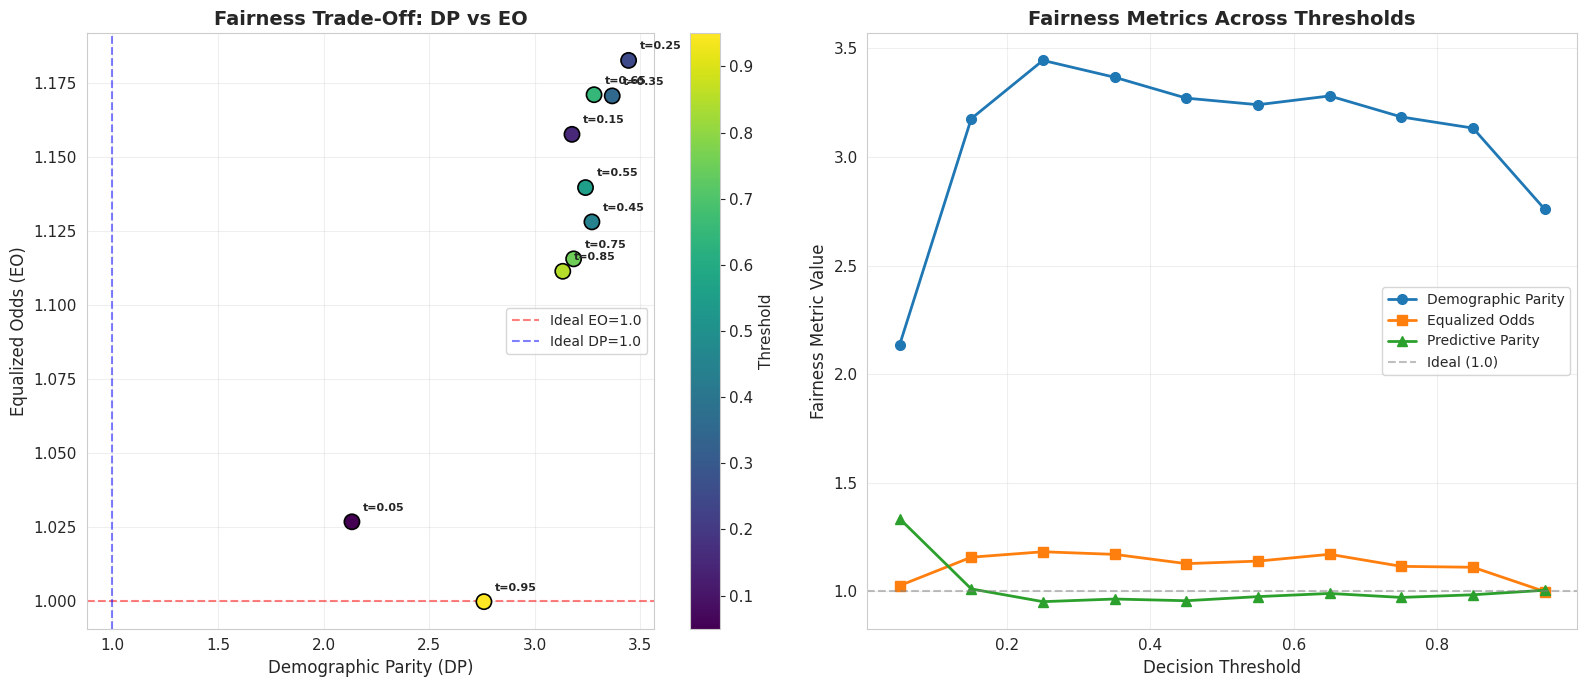

In [19]:
# Fairness Trade-Off Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

dp_vals = fairness_df['DP'].values
eo_vals = fairness_df['EO'].values
pp_vals = fairness_df['PP'].values
t_vals = fairness_df['threshold'].values

# Chart 1: DP vs EO
ax1 = axes[0]
scatter = ax1.scatter(dp_vals, eo_vals, c=t_vals, cmap='viridis', s=120,
                       edgecolors='black', linewidths=1.2, zorder=3)
for i, t in enumerate(t_vals):
    ax1.annotate(f't={t:.2f}', (dp_vals[i], eo_vals[i]),
                 textcoords='offset points', xytext=(8, 8), fontsize=8, fontweight='bold')
ax1.axhline(y=1.0, color='red', linestyle='--', alpha=0.5, label='Ideal EO=1.0')
ax1.axvline(x=1.0, color='blue', linestyle='--', alpha=0.5, label='Ideal DP=1.0')
ax1.set_xlabel('Demographic Parity (DP)', fontsize=12)
ax1.set_ylabel('Equalized Odds (EO)', fontsize=12)
ax1.set_title('Fairness Trade-Off: DP vs EO', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
plt.colorbar(scatter, ax=ax1, label='Threshold')

# Chart 2: All metrics across thresholds
ax2 = axes[1]
ax2.plot(t_vals, dp_vals, 'o-', label='Demographic Parity', linewidth=2, markersize=7)
ax2.plot(t_vals, eo_vals, 's-', label='Equalized Odds', linewidth=2, markersize=7)
ax2.plot(t_vals, pp_vals, '^-', label='Predictive Parity', linewidth=2, markersize=7)
ax2.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5, label='Ideal (1.0)')
ax2.set_xlabel('Decision Threshold', fontsize=12)
ax2.set_ylabel('Fairness Metric Value', fontsize=12)
ax2.set_title('Fairness Metrics Across Thresholds', fontsize=14, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
# Trade-off quantification
print('--- Trade-Off Quantification ---')
for i in range(1, len(fairness_df)):
    dp_change = fairness_df.iloc[i]['DP'] - fairness_df.iloc[i-1]['DP']
    eo_change = fairness_df.iloc[i]['EO'] - fairness_df.iloc[i-1]['EO']
    dp_improvement = abs(1.0 - fairness_df.iloc[i]['DP']) < abs(1.0 - fairness_df.iloc[i-1]['DP'])
    eo_degradation = abs(1.0 - fairness_df.iloc[i]['EO']) > abs(1.0 - fairness_df.iloc[i-1]['EO'])

    if dp_improvement and eo_degradation:
        dp_gain_pct = abs(dp_change / fairness_df.iloc[i-1]['DP']) * 100
        eo_loss_pct = abs(eo_change / fairness_df.iloc[i-1]['EO']) * 100
        cost = eo_loss_pct / dp_gain_pct if dp_gain_pct > 0 else float('inf')
        print(f'  t={fairness_df.iloc[i-1]["threshold"]:.2f} -> t={fairness_df.iloc[i]["threshold"]:.2f}:')
        print(f'    DP: {fairness_df.iloc[i-1]["DP"]:.4f} -> {fairness_df.iloc[i]["DP"]:.4f} ({dp_gain_pct:.1f}% closer to ideal)')
        print(f'    EO: {fairness_df.iloc[i-1]["EO"]:.4f} -> {fairness_df.iloc[i]["EO"]:.4f} ({eo_loss_pct:.1f}% farther from ideal)')
        print(f'    Trade-off cost: {cost:.2f}')

--- Trade-Off Quantification ---
  t=0.45 -> t=0.55:
    DP: 3.2706 -> 3.2403 (0.9% closer to ideal)
    EO: 1.1282 -> 1.1398 (1.0% farther from ideal)
    Trade-off cost: 1.11
